# Estimate Annual Grid Emissions Offset for GM-SEUS Arrays (eGRID + AVERT + Cambium)
NOTE: Requires outputs from getGeneration (annual long generation table and 12x24 generation shapes). Reading eGRID 2005-2010 (.xls) needs `xlrd` in the BigPanel environment.

This script estimates the operational grid carbon emissions offset of every modeled GM-SEUS photovoltaic array for each operating year (installation year to 25 years after installation). For each array and calendar year, offset (t) = annual generation (MWh) x grid emission rate (kg/MWh) / 1000. It is computed three ways, each covering the full historical and future period:

| Version | Question answered | Historical years (before `firstCambiumYear`) | Future years (`firstCambiumYear` onward) |
|---|---|---|---|
| **Average** (attributional) | What share of grid emissions does the array's electricity carry? | EPA eGRID total output rate (`SRC2ERTA`), by eGRID subregion | Cambium average emission rate of generation (`aer_gen_co2e_c`) |
| **Marginal, long-run** (consequential; primary, lower bound) | What emissions does the array avoid, if the grid's future build-out responds to it? | EPA AVERT avoided CO2 rate, utility PV | Cambium long-run marginal emission rate (`lrmer_co2e_c`) |
| **Marginal, short-run** (consequential; upper bound) | What emissions does the array avoid, if it only ever turns down existing power plants? | EPA AVERT avoided CO2 rate, utility PV (same as above) | Cambium short-run marginal emission rate (`srmer_co2e_c`) |

**Marginal bounds: definitions**
* Both bounds use the same historical rates (AVERT). They differ only from `firstCambiumYear` onward, so the range is a statement about the future.
* **Short-run (upper bound)**: each future MWh from the array displaces whichever existing plant would have run next in that hour (in practice, mostly gas). The grid's build-out does not react to the array. This is generous over a 25-year life, because in reality new solar changes what else gets built.
* **Long-run (lower bound, primary)**: each future MWh displaces both operating plants and the capacity the grid would otherwise have built (in Cambium Mid-case, mostly other wind, solar, and storage), so the avoided rate is lower. NLR recommends this metric for long-lived new resources. It is the primary marginal estimate.
* **Historical years use short-run (AVERT) by design**: the past grid's build-out already happened, so the question for past years is which plants the array actually turned down. The drop at `firstCambiumYear` in the long-run version is this change of definition (AVERT 2023 is close to Cambium 2025 short-run; the long-run rate is lower). It is kept, not smoothed; report historical and future totals separately.
* The bounds cover the marginal definition only. Cambium scenario (e.g., low/high renewable energy cost) is a separate uncertainty, run by changing `cambiumScenario`.

**Data sources and processing**
* **eGRID** is annual only; years without an eGRID release are linearly interpolated.
* **AVERT** rates are EPA's pre-generated annual marginal rates, made by running AVERT's hourly dispatch model with a utility PV generation profile (so they already reflect when PV generates). Two EPA files are used: v4.3 (2017-2023, 14 regions) and v2.3 (2007-2018, 10 older regions).
* **Cambium** 2024 solve years are every 5 years (2025-2050); years between are linearly interpolated. Hourly rates are collapsed to month-by-hour (12x24) means and weighted by each array's own 12x24 generation shape (share of annual energy in each month-hour), so the rate reflects when that array generates.
* The year between the last historical year and 2025 is linearly interpolated (e.g., 2024 in the marginal versions: AVERT 2023 to Cambium 2025).

**Marginal-version assumptions (AVERT does not cover every year)**
1. **2017-2023**: AVERT v4.3 rate for the array's AVERT region (assigned by county with EPA's county-to-region table).
2. **2007-2016 (backcast)**: v4.3 regions do not exist before 2017. Each array's 2017 v4.3 rate is scaled by its older v2.3 region's trend: rate(y) = v4.3 rate(2017) x v2.3 rate(y) / v2.3 rate(2017). This keeps the newer regional level and uses the older file only for the year-to-year change. The array's v2.3 region comes from its eGRID subregion (v2.3 regions are aggregations of eGRID subregions; the crosswalk is in the settings cell and is inferred from region names and the v2.3 manual's state lists, not from an EPA table).
3. **Before 2007**: held at the 2007 backcast rate (`heldAtFirstAVERTYear`).
4. **2024**: interpolated between AVERT 2023 and Cambium 2025 (`AVERTtoCambium_interpolated`).
5. **CO2 only**: AVERT reports CO2, not CO2e, so historical marginal rates exclude CH4 and N2O (~1% of grid CO2e). Cambium marginal rates (future) are CO2e.

**Outputs**
* **GMSEUS_GridOffset_Annual_Long**: `arrayID`, `instYr`, `opYr`, `calYr`, `MWh`; average: `rateKgMWh`, `rateSource`, `tCO2e`; marginal: `rateSourceMarginal` (shared by both bounds), `rateMarginalLRKgMWh`, `tCO2eMarginalLR` (long-run, lower bound, primary), `rateMarginalSRKgMWh`, `tCO2eMarginalSR` (short-run, upper bound). `rateSource` values: `eGRID`, `AVERT`, `AVERT_backcast`, `Cambium2024_<scenario>`, or how a year was filled: `heldAtFirst<eGRID|AVERT>Year`, `<eGRID|AVERT>_interpolated`, `<eGRID|AVERT>toCambium_interpolated`, `Cambium_interpolated`, `heldAtLastSolveYear` (after 2050), `heldAtLast<eGRID|AVERT>Year` (array has no Cambium region match).
* **GMSEUS_GridOffset_Annual_Wide**: `arrayID`, `co2Yr1` ... `co2Yr25` (t, average version).
* **GMSEUS_GridOffset_Annual_Wide_MarginalLR** and **_MarginalSR**: same, for the long-run (lower bound, primary) and short-run (upper bound) marginal versions.
* **GMSEUS_GridRates_TimingCheck** (diagnostic, in intermediateProducts): by GEA region, the ratio of generation-weighted to flat annual Cambium rate (how much time of generation matters), for each Cambium metric.

**Other assumptions** (all set as variables in the first code cells)
* Average metric is combustion only (`aer_gen_co2e_c`), matching eGRID total output rates (also combustion only). Cambium rates (all three metrics) are used year by year (interpolated between solve years), not levelized.
* Scenario: Cambium 2024 Mid-case. Other scenarios can be run by changing `cambiumScenario`.
* GWP: Cambium CO2e uses IPCC AR6 100-year GWPs; eGRID CO2e uses AR5. The difference is small.
* Geography: arrays are assigned to eGRID subregions and Cambium GEA regions by centroid, and to AVERT regions by county. Region boundaries differ between sources, which creates a seam at `firstCambiumYear`; the seam is plotted below.
* Operational phase only (no upstream manufacturing, construction, or end-of-life emissions).

# Import Libraries and Variables

In [ ]:
# Import libraries
import os
import re
import io
import zipfile
import requests
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import figureTheme as ft # shared figure theme (utils/figureTheme.py)
ft.apply()

In [ ]:
# Set folder paths
wd = r'S:\Users\stidjaco\R_files\BigPanel'
temp_path = r'F:\BigPanel_Cache'
cambiumCache_path = os.path.join(temp_path, r'Cambium_Cache') # Cambium scenario zips (~850 MB each)
downloaded_path = os.path.join(wd, r'Data\Downloaded')
derived_path = os.path.join(wd, r'Data\Derived')
derivedTemp_path = os.path.join(derived_path, r'intermediateProducts') # non-final files
carbon_path = os.path.join(derived_path, r'carbonOffset')
generation_path = os.path.join(derived_path, r'generation') # getGeneration outputs
genWeatherSource = 'pvgis' # which getGeneration run to use ('pvgis' or 'nsrdb')
figure_path = os.path.join(wd, r'Figures')
grid_path = os.path.join(downloaded_path, r'GridEmissions')

# Set GM-SEUS array path (centroid latitude/longitude used for region assignment)
gmseusArraysPath = os.path.join(downloaded_path, r'SolarDB\GMSEUS_v2_1\SHP\GMSEUS_Arrays_Final_2025_v2_1.shp') # same file as getGeneration

# Set getGeneration output paths (inputs here)
genLong_path = os.path.join(generation_path, r'GMSEUS_Generation_Annual_Long_' + genWeatherSource + '.csv')
genShape_path = os.path.join(generation_path, r'GMSEUS_Generation_Shape12x24_' + genWeatherSource + '.csv')

# Set region boundary paths
geaShp_path = os.path.join(grid_path, r'Cambium\gea_shapefiles\transgrp') # extracted below from the Cambium 2024 'all' zip (gea_mappings_and_shapefiles)
egridShp_path = os.path.join(grid_path, r'eGRID\eGRID_subregions') # EPA eGRID2023 subregion shapefile, downloaded and extracted below (https://www.epa.gov/egrid/egrid-mapping-files)
avert_path = os.path.join(grid_path, r'AVERT') # AVERT rate workbooks and county-to-region table, downloaded below

# Set output paths. Release outputs are CSV; diagnostics and intermediate files go to derivedTemp_path.
offsetLong_path = os.path.join(carbon_path, r'GMSEUS_GridOffset_Annual_Long_' + genWeatherSource + '.csv')
offsetWide_path = os.path.join(carbon_path, r'GMSEUS_GridOffset_Annual_Wide_' + genWeatherSource + '.csv')
offsetWideMarginalLR_path = os.path.join(carbon_path, r'GMSEUS_GridOffset_Annual_Wide_MarginalLR_' + genWeatherSource + '.csv') # long-run marginal (lower bound, primary)
offsetWideMarginalSR_path = os.path.join(carbon_path, r'GMSEUS_GridOffset_Annual_Wide_MarginalSR_' + genWeatherSource + '.csv') # short-run marginal (upper bound)
timingCheck_path = os.path.join(derivedTemp_path, r'GMSEUS_GridRates_TimingCheck.csv')

# Make folders if they do not exist
os.makedirs(cambiumCache_path, exist_ok=True)
os.makedirs(carbon_path, exist_ok=True)
os.makedirs(os.path.join(grid_path, 'Cambium'), exist_ok=True)
os.makedirs(os.path.join(grid_path, 'eGRID'), exist_ok=True)
os.makedirs(avert_path, exist_ok=True)
os.makedirs(figure_path, exist_ok=True)

In [ ]:
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Cambium settings

# Cambium 2024 scenario zips (Catalyst Cooperative Zenodo archive of the NLR release, CC-BY-4.0)
cambiumZenodo = 'https://zenodo.org/records/18036226/files/'
cambiumScenario = 'mid_case' # e.g., 'low_renewable_energy_cost', 'high_renewable_energy_cost'
cambiumZipName = 'nrelcambium2024_' + cambiumScenario + '.zip'
cambiumZip_path = os.path.join(cambiumCache_path, cambiumZipName)

# Cambium 2024 'all' zip (~51 MB): holds the GEA region shapefile (plus month-hour, annual, and GEA historical intensity tables)
cambiumAllZipName = 'nrelcambium2024_all.zip'
cambiumAllZip_path = os.path.join(cambiumCache_path, cambiumAllZipName)
rates12x24_path = os.path.join(derivedTemp_path, r'Cambium_rates12x24_' + cambiumScenario + '.parquet') # intermediate 12x24 rates for this scenario

# The scenario zip holds nested zips; GEA-level hourly csvs (one per GEA and solve year) are in the one whose name contains this
cambiumNestedZipPattern = 'hourly__gea_regions'

# Cambium metric (kg CO2e/MWh). Options: 'aer_gen_co2e_c' (default), 'aer_gen_co2e' (incl. precombustion), 'srmer_co2e_c', 'lrmer_co2e_c'
cambiumMetric = 'aer_gen_co2e_c'

# Marginal metrics, combustion only (kg CO2e/MWh). Long-run (lower bound, primary; Cambium's recommended metric for emissions avoided by new generation) and short-run (upper bound; no build-out response)
cambiumMetricLrmer = 'lrmer_co2e_c'
cambiumMetricSrmer = 'srmer_co2e_c'

# Cambium columns: local standard time timestamp (hour-beginning, first row 00:00), and the GEA metadata field (row 2 of each csv)
cambiumTimeCol = 'timestamp_local'
cambiumRegionCol = 'gea'

# First year taken from Cambium (Cambium solve years: 2025, 2030, ..., 2050)
firstCambiumYear = 2025

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ eGRID settings

# eGRID files by data year: (file path, subregion sheet name, header row). Sheet names, header rows, and SRC2ERTA checked for 2012-2024 (Nov 2026 downloads); 2005-2010 (.xls, need xlrd) checked too; eGRID2005 has no SRC2ERTA, so it uses SRCO2RTA (CO2 only).
# 2018-2023: EPA eGRID detailed data; 2005-2016: EPA historical eGRID zip; 2024: unofficial Cornerstone run of EPA's eGRID code (doi:10.5281/zenodo.18968658)
egridFiles = {
    2005: (os.path.join(grid_path, r'eGRID\eGRID2005_aggregation.xls'), 'SRL05', 4),
    2007: (os.path.join(grid_path, r'eGRID\eGRID2007_aggregation.xls'), 'SRL07', 4),
    2009: (os.path.join(grid_path, r'eGRID\eGRID2009_data.xls'), 'SRL09', 4),
    2010: (os.path.join(grid_path, r'eGRID\eGRID2010_Data.xls'), 'SRL10', 4),
    2012: (os.path.join(grid_path, r'eGRID\eGRID2012_Data.xlsx'), 'SRL12', 4),
    2014: (os.path.join(grid_path, r'eGRID\eGRID2014_Data_v2.xlsx'), 'SRL14', 1),
    2016: (os.path.join(grid_path, r'eGRID\egrid2016_data.xlsx'), 'SRL16', 1),
    2018: (os.path.join(grid_path, r'eGRID\egrid2018_data_v2.xlsx'), 'SRL18', 1),
    2019: (os.path.join(grid_path, r'eGRID\egrid2019_data.xlsx'), 'SRL19', 1),
    2020: (os.path.join(grid_path, r'eGRID\eGRID2020_Data_v2.xlsx'), 'SRL20', 1),
    2021: (os.path.join(grid_path, r'eGRID\eGRID2021_data.xlsx'), 'SRL21', 1),
    2022: (os.path.join(grid_path, r'eGRID\eGRID2022_data.xlsx'), 'SRL22', 1),
    2023: (os.path.join(grid_path, r'eGRID\egrid2023_data_rev2.xlsx'), 'SRL23', 1),
    2024: (os.path.join(grid_path, r'eGRID\egrid2024_data_metric.xlsx'), 'SRL24', 1), # Cornerstone (unofficial); metric file, see egridMetricYears
}

# eGRID download URLs (EPA; Cornerstone for 2024). Files for 2005-2016 come from EPA's historical zip (157 MB) and are extracted into the eGRID folder.
# Pages: https://www.epa.gov/egrid/detailed-data, https://www.epa.gov/egrid/historical-egrid-data, https://www.epa.gov/egrid/egrid-mapping-files
egridHistZipUrl = 'https://www.epa.gov/system/files/other-files/2023-01/egrid_historical_files_1996-2016.zip'
egridUrls = {
    2018: 'https://www.epa.gov/sites/default/files/2020-03/egrid2018_data_v2.xlsx',
    2019: 'https://www.epa.gov/sites/default/files/2021-02/egrid2019_data.xlsx',
    2020: 'https://www.epa.gov/system/files/documents/2022-09/eGRID2020_Data_v2.xlsx',
    2021: 'https://www.epa.gov/system/files/documents/2023-01/eGRID2021_data.xlsx',
    2022: 'https://www.epa.gov/system/files/documents/2024-01/egrid2022_data.xlsx',
    2023: 'https://www.epa.gov/system/files/documents/2025-06/egrid2023_data_rev2.xlsx',
    2024: 'https://zenodo.org/records/18968658/files/egrid2024_data_metric.xlsx?download=1',
}
egridShpZipUrl = 'https://www.epa.gov/system/files/other-files/2025-01/egrid2023_subregions.zip' # eGRID2023 subregion boundaries (57 MB)

# eGRID columns: subregion code and CO2e total output emission rate. Older releases may lack SRC2ERTA; SRCO2RTA (CO2 only) is used as fallback.
egridRegionCol = 'SUBRGN'
egridRateCol = 'SRC2ERTA'
egridRateFallbackCol = 'SRCO2RTA'

# eGRID years whose file is in metric units (kg/MWh) rather than lb/MWh
egridMetricYears = [2024]
lbToKg = 0.45359237

# Use the unofficial eGRID2024? If False, 2024 is interpolated between eGRID2023 and Cambium 2025.
useEgrid2024Cornerstone = True

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ AVERT settings (historical marginal rates)

# EPA pre-generated AVERT avoided emission rates (https://www.epa.gov/avert/avoided-emission-rates-generated-avert). One sheet per data year.
avertFiles = {
    'v4': ('https://www.epa.gov/system/files/documents/2024-04/avert_emission_rates_04-11-24_0.xlsx', os.path.join(avert_path, 'avert_emission_rates_04-11-24_0.xlsx')), # v4.3, 2017-2023, 14 regions
    'v2': ('https://www.epa.gov/system/files/other-files/2021-09/avert_emission_rates_05-30-19.xlsx', os.path.join(avert_path, 'avert_emission_rates_05-30-19.xlsx')), # v2.3, 2007-2018, 10 regions
}

# EPA county-to-AVERT-region table (v4 regions), from the AVERT web edition source, pinned to a commit for reproducibility
avertCountyUrl = 'https://raw.githubusercontent.com/USEPA/AVERT/d7188824f6de16e443bcd77c43e3fb0b6da77577/web/client/src/data/county-fips.json'
avertCounty_path = os.path.join(avert_path, 'avert_county_fips.json')
avertCountyFipsAlias = {'46102': '46113'} # Oglala Lakota County, SD (renamed 2015; AVERT table uses the old code)

# Rate used: avoided CO2 (lb/MWh) for utility-scale PV (column name in both files)
avertTechCol = 'Utility PV'

# Backcast: years before avertSpliceYear use the v4 rate in avertSpliceYear scaled by the v2 region's trend (v2 year / v2 avertSpliceYear)
avertSpliceYear = 2017

# eGRID subregion -> AVERT v2.3 region. v2.3 regions are aggregations of eGRID2010 subregions (AVERT v2.3 manual, Appendix G); EPA does not publish the list,
# so this is inferred from region names and the manual's state lists (Table 1). Least certain: MROE (eastern WI) and SRMW (Ameren MO/IL). Only affects the 2007-2016 trend.
egridToAvertV2 = {
    'NEWE': 'Northeast', 'NYUP': 'Northeast', 'NYCW': 'Northeast', 'NYLI': 'Northeast',
    'RFCE': 'Great Lakes/Mid-Atlantic', 'RFCM': 'Great Lakes/Mid-Atlantic', 'RFCW': 'Great Lakes/Mid-Atlantic', 'MROE': 'Great Lakes/Mid-Atlantic',
    'SRSO': 'Southeast', 'SRTV': 'Southeast', 'SRVC': 'Southeast', 'SRMV': 'Southeast', 'FRCC': 'Southeast',
    'SPNO': 'Lower Midwest', 'SPSO': 'Lower Midwest',
    'MROW': 'Upper Midwest', 'SRMW': 'Upper Midwest',
    'RMPA': 'Rocky Mountains', 'ERCT': 'Texas', 'AZNM': 'Southwest', 'NWPP': 'Northwest', 'CAMX': 'California',
} # AKGD, AKMS, HIMS, HIOA, PRMS: not in AVERT

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Region boundary settings (field names checked against the downloaded shapefiles)

geaNameCol = 'transgrp' # GEA name field in transgrp.shp (18 regions, names match Cambium 'gea')
egridNameCol = 'Subregion' # eGRID2023_Subregions.shp (27 subregions, codes match SUBRGN)
regionCRS = 'EPSG:4269' # NAD83, matching GM-SEUS latitude/longitude

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Data conventions

noData = -9999
arrayIDcol = 'arrayID'
nYears = 25
shapeCols = ['m' + str(m).zfill(2) + 'h' + str(h).zfill(2) for m in range(1, 13) for h in range(24)]

# Helper Functions

In [ ]:
# A function to download a file with streaming (skips if already downloaded)
def downloadFile(url, outPath):
    if os.path.exists(outPath):
        print('Exists, skipping:', outPath)
        return outPath
    with requests.get(url, stream=True, timeout=300, headers={'User-Agent': 'Mozilla/5.0 (research data download script)'}) as r:
        r.raise_for_status()
        with open(outPath, 'wb') as f:
            for chunk in r.iter_content(chunk_size=8 * 1024 * 1024):
                f.write(chunk)
    print('Downloaded:', outPath)
    return outPath

# A function to read one Cambium hourly csv (bytes). Rows 1-2 are metadata (field names, values; includes gea and t), the column header row starts with 'timestamp'.
def readCambiumCsv(csvBytes):
    raw = csvBytes.decode('utf-8-sig', errors='ignore').splitlines()
    meta = dict(zip(raw[0].split(','), raw[1].split(',')))
    headerRow = next(i for i, line in enumerate(raw) if line.lower().startswith('timestamp'))
    df = pd.read_csv(io.StringIO('\n'.join(raw[headerRow:])), usecols=lambda c: c in [cambiumTimeCol, cambiumMetric, cambiumMetricLrmer, cambiumMetricSrmer])
    missingCols = {cambiumTimeCol, cambiumMetric, cambiumMetricLrmer, cambiumMetricSrmer} - set(df.columns)
    assert not missingCols, 'missing ' + str(missingCols)
    df[cambiumRegionCol] = meta[cambiumRegionCol]
    df['solveYear'] = int(meta['t'])
    return df

# A function to read eGRID subregion rates for one year (returns region, year, rateKgMWh)
def readEgridYear(year, filePath, sheet, headerRow):
    xl = pd.ExcelFile(filePath)
    sheetMatch = next(s for s in xl.sheet_names if s.strip() == sheet) # some EPA sheet names have trailing spaces (e.g., 'SRL05 ')
    df = xl.parse(sheetMatch, header=headerRow)
    df.columns = [str(c).strip() for c in df.columns]
    rateCol = egridRateCol if egridRateCol in df.columns else egridRateFallbackCol
    out = df[[egridRegionCol, rateCol]].dropna().copy()
    out.columns = ['egridRegion', 'rateKgMWh']
    out['rateKgMWh'] = out['rateKgMWh'].astype(float) * (1.0 if year in egridMetricYears else lbToKg)
    out['year'] = year
    out['rateCol'] = rateCol
    return out

# A function to read AVERT regional avoided CO2 rates (kg/MWh) for one technology from an EPA rate workbook (one sheet per year)
# Layout: a 'Regional Emission Rates' row, then a header row with technology names; the CO2 block is the first set of columns, regions in column 0
def readAvertRates(filePath, techCol):
    out = []
    for sheet in [s for s in pd.ExcelFile(filePath).sheet_names if s.strip().isdigit()]:
        df = pd.read_excel(filePath, sheet_name=sheet, header=None)
        startRow = df.index[df[0].astype(str).str.strip() == 'Regional Emission Rates'][0]
        headerRow = next(r for r in range(startRow, len(df)) if techCol in df.loc[r].astype(str).str.strip().values)
        col = next(c for c in df.columns if str(df.loc[headerRow, c]).strip() == techCol) # first match = CO2 block
        for r in range(headerRow + 1, len(df)):
            rate = pd.to_numeric(df.loc[r, col], errors='coerce')
            if pd.isna(rate): break # end of the regional CO2 table
            out.append({'avertRegion': str(df.loc[r, 0]).strip(), 'year': int(sheet), 'rateKgMWh': rate * lbToKg})
    return pd.DataFrame(out)

# A function to assign each array point to a polygon region, with nearest-polygon fallback for points just outside (e.g., coastline)
def assignRegion(pointsGDF, regionsGDF, nameCol, outCol):
    joined = gpd.sjoin(pointsGDF, regionsGDF[[nameCol, 'geometry']], how='left', predicate='within')
    joined = joined[~joined.index.duplicated()]
    missing = joined[nameCol].isna()
    if missing.any():
        nearest = gpd.sjoin_nearest(pointsGDF[missing].to_crs('EPSG:6350'), regionsGDF[[nameCol, 'geometry']].to_crs('EPSG:6350'), how='left')
        nearest = nearest[~nearest.index.duplicated()]
        joined.loc[missing, nameCol] = nearest[nameCol]
    print(outCol, '| assigned by nearest polygon:', missing.sum())
    return joined[nameCol].rename(outCol)

# Download Data
Every input this script needs is downloaded here if it is missing (files already present are skipped), so a fresh run reproduces the inputs from code. URLs are set in the settings cells.
* **eGRID** (EPA; Cornerstone for 2024): annual subregion rate tables, 2005-2024, and the eGRID2023 subregion shapefile.
* **AVERT** (EPA): pre-generated avoided emission rate workbooks (v4.3 and v2.3) and the county-to-region table.
* **Cambium 2024** (Zenodo archive of the NLR release): the 'all' zip (~51 MB) for the GEA region shapefile, and the scenario zip (~850 MB) for hourly rates.

In [ ]:
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ eGRID

# Download eGRID files that are missing (skips files already present)
egridDir = os.path.join(grid_path, 'eGRID')
for year, (filePath, sheet, headerRow) in egridFiles.items():
    if os.path.exists(filePath) or ((year == 2024) and not useEgrid2024Cornerstone):
        continue
    if year in egridUrls:
        downloadFile(egridUrls[year], filePath)
    else: # 2005-2016: extract this file from EPA's historical zip
        histZip_path = downloadFile(egridHistZipUrl, os.path.join(egridDir, 'egrid_historical_files_1996-2016.zip'))
        with zipfile.ZipFile(histZip_path) as hz:
            member = next(m for m in hz.namelist() if os.path.basename(m).lower() == os.path.basename(filePath).lower())
            with open(filePath, 'wb') as f:
                f.write(hz.read(member))
        print('Extracted:', filePath)

# Download and extract the eGRID subregion shapefile
if not any(f.endswith('.shp') for _, _, fs in os.walk(egridShp_path) for f in fs):
    shpZip_path = downloadFile(egridShpZipUrl, os.path.join(egridDir, os.path.basename(egridShpZipUrl)))
    zipfile.ZipFile(shpZip_path).extractall(egridShp_path)
print('eGRID shapefiles:', [os.path.join(r, f) for r, _, fs in os.walk(egridShp_path) for f in fs if f.endswith('.shp')])

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ AVERT

for url, filePath in avertFiles.values():
    downloadFile(url, filePath)
downloadFile(avertCountyUrl, avertCounty_path)

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Cambium

# Download the Cambium 'all' zip and extract the GEA shapefile (nested zips: all -> gea_mappings_and_shapefiles -> gea_shapefiles)
if not os.path.exists(os.path.join(geaShp_path, 'transgrp.shp')):
    downloadFile(cambiumZenodo + cambiumAllZipName + '?download=1', cambiumAllZip_path)
    allZip = zipfile.ZipFile(cambiumAllZip_path)
    mapZip = zipfile.ZipFile(io.BytesIO(allZip.read(next(m for m in allZip.namelist() if 'gea_mappings_and_shapefiles' in m))))
    zipfile.ZipFile(io.BytesIO(mapZip.read('gea_shapefiles.zip'))).extractall(os.path.dirname(geaShp_path))

# Download the Cambium scenario zip (~850 MB; skipped if present)
downloadFile(cambiumZenodo + cambiumZipName + '?download=1', cambiumZip_path)


eGRID shapefiles: ['S:\\Users\\stidjaco\\R_files\\BigPanel\\Data\\Downloaded\\GridEmissions\\eGRID\\eGRID_subregions\\eGRID2023_Subregions.shp']
Exists, skipping: S:\Users\stidjaco\R_files\BigPanel\Data\Downloaded\GridEmissions\AVERT\avert_emission_rates_04-11-24_0.xlsx
Exists, skipping: S:\Users\stidjaco\R_files\BigPanel\Data\Downloaded\GridEmissions\AVERT\avert_emission_rates_05-30-19.xlsx
Exists, skipping: S:\Users\stidjaco\R_files\BigPanel\Data\Downloaded\GridEmissions\AVERT\avert_county_fips.json
Exists, skipping: F:\BigPanel_Cache\Cambium_Cache\nrelcambium2024_mid_case.zip


'F:\\BigPanel_Cache\\Cambium_Cache\\nrelcambium2024_mid_case.zip'

# Assign Arrays to Grid Regions

In [ ]:
# Call GM-SEUS arrays and create centroid points from latitude/longitude
gmseusArrays = gpd.read_file(gmseusArraysPath)
arrayPts = gpd.GeoDataFrame(gmseusArrays[[arrayIDcol, 'STATEFP', 'COUNTYFP']].copy(), geometry=gpd.points_from_xy(gmseusArrays['longitude'], gmseusArrays['latitude']), crs=regionCRS)

# Call region boundaries and print columns
geaRegions = gpd.read_file(geaShp_path).to_crs(regionCRS)
egridRegions = gpd.read_file(egridShp_path).to_crs(regionCRS)
print('GEA columns:', list(geaRegions.columns), '| n =', len(geaRegions))
print('eGRID columns:', list(egridRegions.columns), '| n =', len(egridRegions))

GEA columns: ['transgrp', 'OBJECTID_1', 'st', 'rto', 'interconne', 'country', 'custreg', 'nercr', 'transreg', 'cendiv', 'intercon_1', 'st_interco', 'usda_regio', 'aggreg', 'labelx', 'labely', 'x', 'y', 'geometry'] | n = 18
eGRID columns: ['Subregion', 'Shape_Leng', 'Shape_Area', 'geometry'] | n = 27


In [ ]:
# Assign GEA region and eGRID subregion to each array
arrayRegions = arrayPts[[arrayIDcol]].copy()
arrayRegions['geaRegion'] = assignRegion(arrayPts, geaRegions, geaNameCol, 'geaRegion')
arrayRegions['egridRegion'] = assignRegion(arrayPts, egridRegions, egridNameCol, 'egridRegion')
arrayRegions = pd.DataFrame(arrayRegions)

# Assign AVERT v4 region by county FIPS (EPA table stores some codes as numbers, so normalize to 5-digit strings)
avertCounty = pd.read_json(avertCounty_path, dtype={'State and County FIPS Code': str})[['State and County FIPS Code', 'AVERT Region']]
avertCounty['fips'] = avertCounty['State and County FIPS Code'].astype(str).str.split('.').str[0].str.zfill(5)
arrayFips = (arrayPts['STATEFP'].astype(str).str.zfill(2) + arrayPts['COUNTYFP'].astype(str).str.zfill(3)).replace(avertCountyFipsAlias)
arrayRegions['avertRegion'] = arrayFips.map(avertCounty.set_index('fips')['AVERT Region']).values

# Assign AVERT v2 region (for the 2007-2016 backcast trend) from the eGRID subregion
arrayRegions['avertV2Region'] = arrayRegions['egridRegion'].map(egridToAvertV2)
print('Arrays without AVERT v4 / v2 region:', arrayRegions['avertRegion'].isna().sum(), '/', arrayRegions['avertV2Region'].isna().sum())

# Print array counts by region
print(arrayRegions['geaRegion'].value_counts())
print(arrayRegions['egridRegion'].value_counts())
print(arrayRegions['avertRegion'].value_counts())

geaRegion | assigned by nearest polygon: 31
egridRegion | assigned by nearest polygon: 5
Arrays without AVERT v4 / v2 region: 0 / 0
geaRegion
CAISO                 5063
ISONE                 2378
PJM_East              1948
SERTP                 1926
MISO_North            1176
NYISO                 1070
MISO_Central           960
WestConnect_South      865
ERCOT                  463
WestConnect_North      438
SPP_South              429
FRCC                   343
NorthernGrid_South     336
NorthernGrid_West      313
PJM_West               286
MISO_South             230
NorthernGrid_East      191
SPP_North               87
Name: count, dtype: int64
egridRegion
CAMX    4900
NEWE    2378
SRVC    1358
RFCE    1246
RFCW    1147
AZNM    1113
MROW    1049
NYUP    1010
NWPP     754
SRSO     541
SRMW     468
RMPA     452
ERCT     431
FRCC     359
SRTV     256
SPNO     244
SRMV     236
RFCM     224
SPSO     165
MROE     108
NYLI      45
NYCW      18
Name: count, dtype: int64
avertRegion
California

# Historical Rates: eGRID

In [ ]:
# Read every available eGRID year (skip 2024 if not using the unofficial release)
egridRates = []
for year, (filePath, sheet, headerRow) in egridFiles.items():
    if (year == 2024) and not useEgrid2024Cornerstone:
        continue
    if not os.path.exists(filePath):
        print('Missing eGRID file, skipping:', year, filePath)
        continue
    egridRates.append(readEgridYear(year, filePath, sheet, headerRow))
egridRates = pd.concat(egridRates, ignore_index=True)

# Print years read, the rate column used for each year, and a sanity summary (US subregion rates typically ~100-1,000 kg CO2e/MWh)
print(egridRates.groupby('year')['rateCol'].first())
print(egridRates.groupby('year')['rateKgMWh'].describe()[['count', 'min', '50%', 'max']].round(0))

year
2005    SRCO2RTA
2007    SRC2ERTA
2009    SRC2ERTA
2010    SRC2ERTA
2012    SRC2ERTA
2014    SRC2ERTA
2016    SRC2ERTA
2018    SRC2ERTA
2019    SRC2ERTA
2020    SRC2ERTA
2021    SRC2ERTA
2022    SRC2ERTA
2023    SRC2ERTA
2024    SRC2ERTA
Name: rateCol, dtype: object
      count    min    50%    max
year                            
2005   26.0  226.0  638.0  889.0
2007   26.0  244.0  599.0  869.0
2009   26.0  227.0  593.0  832.0
2010   26.0  204.0  589.0  865.0
2012   26.0  186.0  536.0  831.0
2014   26.0  167.0  505.0  810.0
2016   26.0  134.0  493.0  762.0
2018   26.0  115.0  470.0  766.0
2019   27.0  106.0  442.0  775.0
2020   27.0  106.0  392.0  755.0
2021   27.0  106.0  425.0  746.0
2022   27.0  125.0  426.0  726.0
2023   27.0  110.0  394.0  702.0
2024   27.0  124.0  387.0  726.0


# Historical Marginal Rates: AVERT
AVERT v4.3 rates are used directly for 2017-2023. For 2007-2016, each array's 2017 v4.3 rate is scaled by its v2.3 region's trend relative to 2017 (see assumptions at top).

In [ ]:
# Read AVERT utility PV avoided CO2 rates (kg/MWh) from both workbooks
avertV4 = readAvertRates(avertFiles['v4'][1], avertTechCol)
avertV2 = readAvertRates(avertFiles['v2'][1], avertTechCol).rename(columns={'avertRegion': 'avertV2Region'})
print('v4 years:', sorted(avertV4['year'].unique()), '| regions:', avertV4['avertRegion'].nunique())
print('v2 years:', sorted(avertV2['year'].unique()), '| regions:', avertV2['avertV2Region'].nunique())
print('Array AVERT regions missing from rates:', set(arrayRegions['avertRegion'].dropna()) - set(avertV4['avertRegion']), set(arrayRegions['avertV2Region'].dropna()) - set(avertV2['avertV2Region']))

# Check: v2 and v4 in the overlap year for regions with the same name (differences come from new region boundaries and model updates)
overlap = avertV4[avertV4['year'] == avertSpliceYear].merge(avertV2[avertV2['year'] == avertSpliceYear], left_on='avertRegion', right_on='avertV2Region', suffixes=('V4', 'V2'))
print(overlap[['avertRegion', 'rateKgMWhV4', 'rateKgMWhV2']].round(0))

# 2017-2023: v4 rate for the array's region
regionsAvert = arrayRegions[[arrayIDcol, 'avertRegion', 'avertV2Region']]
avertDirect = regionsAvert.merge(avertV4, on='avertRegion')[[arrayIDcol, 'year', 'rateKgMWh']].assign(rateSource='AVERT')

# 2007-2016: v4 rate in the splice year x v2 trend (v2 year / v2 splice year)
v2Trend = avertV2.merge(avertV2[avertV2['year'] == avertSpliceYear][['avertV2Region', 'rateKgMWh']], on='avertV2Region', suffixes=('', 'Splice'))
v2Trend = v2Trend[v2Trend['year'] < avertSpliceYear].assign(trend=lambda d: d['rateKgMWh'] / d['rateKgMWhSplice'])[['avertV2Region', 'year', 'trend']]
base = avertDirect[avertDirect['year'] == avertSpliceYear][[arrayIDcol, 'rateKgMWh']]
avertBack = regionsAvert.merge(base, on=arrayIDcol).merge(v2Trend, on='avertV2Region')
avertBack = avertBack.assign(rateKgMWh=avertBack['rateKgMWh'] * avertBack['trend'], rateSource='AVERT_backcast')[[arrayIDcol, 'year', 'rateKgMWh', 'rateSource']]
avertEff = pd.concat([avertBack, avertDirect], ignore_index=True)

# Print v2 trend by region (2007 and 2012 relative to 2017) and the array-median rate by year
print(v2Trend[v2Trend['year'].isin([2007, 2012])].pivot(index='avertV2Region', columns='year', values='trend').round(2))
print(avertEff.groupby('year')['rateKgMWh'].median().round(0))

v4 years: [2017, 2018, 2019, 2020, 2021, 2022, 2023] | regions: 14
v2 years: [2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018] | regions: 10
Array AVERT regions missing from rates: set() set()
       avertRegion  rateKgMWhV4  rateKgMWhV2
0       California        481.0        477.0
1        Northwest        682.0        722.0
2  Rocky Mountains        776.0        709.0
3        Southeast        657.0        659.0
4        Southwest        601.0        575.0
5            Texas        571.0        574.0
year                      2007  2012
avertV2Region                       
California                1.04  1.02
Great Lakes/Mid-Atlantic  1.07  1.09
Lower Midwest             0.90  0.96
Northeast                 1.22  1.09
Northwest                 0.98  1.03
Rocky Mountains           1.02  1.14
Southeast                 1.02  1.06
Southwest                 0.88  0.95
Texas                     0.97  1.09
Upper Midwest             1.01  1.02
year
2007    611.0
2008  

# Future Rates: Cambium
## Inspect Zip Contents

In [ ]:
# Open the scenario zip, then the nested GEA-level hourly zip, and list its csv files (one per GEA and solve year)
cambiumZip = zipfile.ZipFile(cambiumZip_path)
print('Nested zips:', cambiumZip.namelist())
geaHourlyName = next(m for m in cambiumZip.namelist() if cambiumNestedZipPattern in m)
geaHourlyZip = zipfile.ZipFile(io.BytesIO(cambiumZip.read(geaHourlyName)))
cambiumMembers = sorted(m for m in geaHourlyZip.namelist() if m.lower().endswith('.csv'))
print('Selected:', geaHourlyName, '|', len(cambiumMembers), 'csv files'); print(cambiumMembers[:5])

Nested zips: ['nrelcambium2024_2024__mid_case__all__month_hour__balancing_areas.zip', 'nrelcambium2024_2024__mid_case__all__hourly__nations.zip', 'nrelcambium2024_2024__mid_case__all__hourly__gea_regions.zip', 'nrelcambium2024_2024__mid_case__all__hourly__balancing_areas.zip']
Selected: nrelcambium2024_2024__mid_case__all__hourly__gea_regions.zip | 108 csv files
['hourly_gea/Cambium24_MidCase_hourly_CAISO_2025.csv', 'hourly_gea/Cambium24_MidCase_hourly_CAISO_2030.csv', 'hourly_gea/Cambium24_MidCase_hourly_CAISO_2035.csv', 'hourly_gea/Cambium24_MidCase_hourly_CAISO_2040.csv', 'hourly_gea/Cambium24_MidCase_hourly_CAISO_2045.csv']


## Collapse Hourly Rates to 12x24 by GEA Region and Solve Year

In [ ]:
# Loop through selected files, read metric, and average to month x hour by region and year
rates12x24 = []
for member in cambiumMembers:

    # Read csv (one GEA and solve year); month and hour from the local standard time timestamp
    camDF = readCambiumCsv(geaHourlyZip.read(member))
    camDF['ts'] = pd.to_datetime(camDF[cambiumTimeCol])
    camDF['year'] = camDF['solveYear']
    camDF['month'] = camDF['ts'].dt.month
    camDF['hour'] = camDF['ts'].dt.hour

    # Mean rate per region, year, month, hour
    rates12x24.append(camDF.groupby([cambiumRegionCol, 'year', 'month', 'hour'])[[cambiumMetric, cambiumMetricLrmer, cambiumMetricSrmer]].mean().reset_index())

# Combine and rename
rates12x24 = pd.concat(rates12x24, ignore_index=True).rename(columns={cambiumRegionCol: 'geaRegion', cambiumMetric: 'rateKgMWh', cambiumMetricLrmer: 'rateLrmerKgMWh', cambiumMetricSrmer: 'rateSrmerKgMWh'})
rates12x24 = rates12x24.groupby(['geaRegion', 'year', 'month', 'hour'], as_index=False)[['rateKgMWh', 'rateLrmerKgMWh', 'rateSrmerKgMWh']].mean()

# Checks: solve years, regions, and every region-year has 288 cells
print('Solve years:', sorted(rates12x24['year'].unique()))
print('GEA regions:', rates12x24['geaRegion'].nunique())
assert (rates12x24.groupby(['geaRegion', 'year']).size() == 288).all()
print(rates12x24.groupby('year')[['rateKgMWh', 'rateLrmerKgMWh', 'rateSrmerKgMWh']].mean().round(0)) # mean 12x24 rate by solve year, each metric

# Check that array GEA names match Cambium names
print('Array GEA regions missing from Cambium:', set(arrayRegions['geaRegion'].dropna()) - set(rates12x24['geaRegion']))

# Export 12x24 rates
rates12x24.to_parquet(rates12x24_path)

Solve years: [2025, 2030, 2035, 2040, 2045, 2050]
GEA regions: 18
      rateKgMWh  rateLrmerKgMWh  rateSrmerKgMWh
year                                           
2025      260.0           411.0           642.0
2030      144.0           215.0           478.0
2035       69.0           100.0           287.0
2040       58.0            95.0           264.0
2045       52.0            83.0           249.0
2050       49.0            81.0           242.0
Array GEA regions missing from Cambium: set()


# Effective Rate per Array and Year
For Cambium years, each array's effective rate is its generation-weighted 12x24 rate (average and LRMER). For eGRID and AVERT years, the annual rate is used as-is. Years between available data years are linearly interpolated per array; years beyond the last Cambium solve year are held at the last value.

In [ ]:
# Call generation outputs
genLong = pd.read_csv(genLong_path)
genShape = pd.read_csv(genShape_path)

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Cambium: generation-weighted rate per array and solve year

# Pivot rates to wide 12x24 vectors per region and year (columns in the same order as shapeCols), one table per metric
rateVars = {'rateKgMWh': 'rateFlatKgMWh', 'rateLrmerKgMWh': 'rateLrmerFlatKgMWh', 'rateSrmerKgMWh': 'rateSrmerFlatKgMWh'} # generation-weighted column: flat column
ratesLong = rates12x24.assign(cell='m' + rates12x24['month'].astype(str).str.zfill(2) + 'h' + rates12x24['hour'].astype(str).str.zfill(2))
ratesWide = {v: ratesLong.pivot_table(index=['geaRegion', 'year'], columns='cell', values=v)[shapeCols] for v in rateVars}

# Join array shapes to regions, then for each solve year and metric compute sum(shape x rate)
shapeRegion = genShape.merge(arrayRegions[[arrayIDcol, 'geaRegion']], on=arrayIDcol, how='left')
cambiumEff = []
for year in sorted(rates12x24['year'].unique()):
    yearDF = pd.DataFrame({arrayIDcol: shapeRegion[arrayIDcol], 'year': year, 'rateSource': 'Cambium2024_' + cambiumScenario})
    for v, vFlat in rateVars.items():
        rMatched = ratesWide[v].xs(year, level='year').reindex(shapeRegion['geaRegion']).values
        yearDF[v] = np.sum(shapeRegion[shapeCols].values * rMatched, axis=1) # NaN (not 0) if the array's GEA has no Cambium rates
        yearDF[vFlat] = np.mean(rMatched, axis=1) # unweighted mean of the 288 month-hour cells
    cambiumEff.append(yearDF)
cambiumEff = pd.concat(cambiumEff, ignore_index=True)
print('Arrays without a Cambium rate (no GEA match):', cambiumEff.loc[cambiumEff['rateKgMWh'].isna(), arrayIDcol].nunique())
cambiumEff = cambiumEff.dropna(subset=['rateKgMWh'])

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ eGRID: annual rate per array and eGRID year (before firstCambiumYear)

egridEff = arrayRegions[[arrayIDcol, 'egridRegion']].merge(egridRates[egridRates['year'] < firstCambiumYear], on='egridRegion', how='inner')
egridEff = egridEff[[arrayIDcol, 'year', 'rateKgMWh']].assign(rateSource='eGRID')
print('Arrays without an eGRID rate (no subregion match):', len(set(genShape[arrayIDcol]) - set(egridEff[arrayIDcol])))
print('Arrays without an AVERT rate (no region match):', len(set(genShape[arrayIDcol]) - set(avertEff[arrayIDcol])))

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Interpolate to every calendar year needed by each array

# A function to interpolate each array's anchor rates (historical years + Cambium solve years) to its calendar years and label the source of each year
def interpolateRates(anchors, histName):
    anchorsByArray = {aid: grp for aid, grp in anchors.sort_values([arrayIDcol, 'year']).groupby(arrayIDcol)}
    rows = []
    for aid, calYrs in genLong.groupby(arrayIDcol)['calYr']:
        grp = anchorsByArray.get(aid)
        if grp is None:
            continue
        calYrs = calYrs.values
        rate = np.interp(calYrs, grp['year'].values, grp['rateKgMWh'].values) # flat beyond first/last anchor
        srcLookup = dict(zip(grp['year'], grp['rateSource']))
        firstYr, lastYr, lastHist = grp['year'].min(), grp['year'].max(), grp.loc[grp['year'] < firstCambiumYear, 'year'].max()
        def fillLabel(y):
            if y < firstYr: return 'heldAtFirst' + histName + 'Year'
            if y > lastYr: return 'heldAtLastSolveYear' if lastYr >= firstCambiumYear else 'heldAtLast' + histName + 'Year' # latter = no Cambium match
            if y < lastHist: return histName + '_interpolated'
            return histName + 'toCambium_interpolated' if y < firstCambiumYear else 'Cambium_interpolated'
        rows.append(pd.DataFrame({arrayIDcol: aid, 'calYr': calYrs, 'rate': rate, 'source': [srcLookup.get(y, fillLabel(y)) for y in calYrs]}))
    return pd.concat(rows, ignore_index=True)

# Average version: eGRID + Cambium average rate. Marginal versions: AVERT + Cambium LRMER (long-run, lower bound) or SRMER (short-run, upper bound).
def cambiumAnchors(col): return cambiumEff[[arrayIDcol, 'year', col, 'rateSource']].rename(columns={col: 'rateKgMWh'})
ratesAvg = interpolateRates(pd.concat([egridEff, cambiumAnchors('rateKgMWh')], ignore_index=True), 'eGRID').rename(columns={'rate': 'rateKgMWh', 'source': 'rateSource'})
ratesLR = interpolateRates(pd.concat([avertEff, cambiumAnchors('rateLrmerKgMWh')], ignore_index=True), 'AVERT').rename(columns={'rate': 'rateMarginalLRKgMWh', 'source': 'rateSourceMarginal'})
ratesSR = interpolateRates(pd.concat([avertEff, cambiumAnchors('rateSrmerKgMWh')], ignore_index=True), 'AVERT').rename(columns={'rate': 'rateMarginalSRKgMWh', 'source': 'rateSourceMarginal'})
assert ratesLR[[arrayIDcol, 'calYr', 'rateSourceMarginal']].equals(ratesSR[[arrayIDcol, 'calYr', 'rateSourceMarginal']]) # same anchors, so the source labels are shared
arrayRates = ratesAvg.merge(ratesLR, on=[arrayIDcol, 'calYr'], how='outer').merge(ratesSR.drop(columns='rateSourceMarginal'), on=[arrayIDcol, 'calYr'], how='outer')

print(arrayRates['rateSource'].value_counts())
print(arrayRates['rateSourceMarginal'].value_counts())

Arrays without a Cambium rate (no GEA match): 0
Arrays without an eGRID rate (no subregion match): 0
Arrays without an AVERT rate (no region match): 0
rateSource
Cambium_interpolated    258472
eGRID                   112250
Cambium2024_mid_case     73905
eGRID_interpolated       17569
heldAtFirsteGRIDYear        29
Name: count, dtype: int64
rateSourceMarginal
Cambium_interpolated           258472
AVERT                           87742
Cambium2024_mid_case            73905
AVERT_backcast                  23847
AVERTtoCambium_interpolated     18151
heldAtFirstAVERTYear              108
Name: count, dtype: int64


# Calculate Annual Offsets and Build Output Tables

In [ ]:
# Join rates to generation and compute offset (t): average, long-run marginal (lower bound, primary), short-run marginal (upper bound). Historical marginal (AVERT) is CO2 only.
offsetLong = genLong.merge(arrayRates, on=[arrayIDcol, 'calYr'], how='left')
offsetLong['tCO2e'] = offsetLong['MWh'] * offsetLong['rateKgMWh'] / 1000
offsetLong['tCO2eMarginalLR'] = offsetLong['MWh'] * offsetLong['rateMarginalLRKgMWh'] / 1000
offsetLong['tCO2eMarginalSR'] = offsetLong['MWh'] * offsetLong['rateMarginalSRKgMWh'] / 1000

# Wide table: co2Yr1 ... co2YrN for every GM-SEUS array (non-modeled = -9999)
def toWide(valueCol):
    w = offsetLong.pivot(index=arrayIDcol, columns='opYr', values=valueCol)
    w.columns = ['co2Yr' + str(c) for c in w.columns]
    return gmseusArrays[[arrayIDcol]].merge(w.reset_index(), on=arrayIDcol, how='left').fillna(noData)
offsetWide = toWide('tCO2e')
offsetWideMarginalLR = toWide('tCO2eMarginalLR')
offsetWideMarginalSR = toWide('tCO2eMarginalSR')

# Checks: no missing rates for modeled arrays; bounds ordered (SR >= LR in future years; identical before)
tCols = {'average': 'tCO2e', 'marginal LR (lower, primary)': 'tCO2eMarginalLR', 'marginal SR (upper)': 'tCO2eMarginalSR'}
print('Rows with missing rate:', offsetLong[['rateKgMWh', 'rateMarginalLRKgMWh', 'rateMarginalSRKgMWh']].isna().sum().to_dict())
hist = offsetLong['calYr'] < firstCambiumYear
print('Marginal bounds identical before', firstCambiumYear, ':', np.allclose(offsetLong.loc[hist & (offsetLong['calYr'] < firstCambiumYear - 1), 'tCO2eMarginalLR'], offsetLong.loc[hist & (offsetLong['calYr'] < firstCambiumYear - 1), 'tCO2eMarginalSR']),
      '| share of future rows with SR >= LR:', round((offsetLong.loc[~hist, 'rateMarginalSRKgMWh'] >= offsetLong.loc[~hist, 'rateMarginalLRKgMWh']).mean(), 3))

# Totals (Mt): historical, future, lifetime
totals = pd.DataFrame({name: [offsetLong.loc[hist, c].sum() / 1e6, offsetLong.loc[~hist, c].sum() / 1e6, offsetLong[c].sum() / 1e6] for name, c in tCols.items()},
                      index=['historical (before ' + str(firstCambiumYear) + ')', 'future', 'lifetime ' + str(nYears) + ' yr'])
print(totals.round(1).to_string())

Rows with missing rate: {'rateKgMWh': 0, 'rateMarginalLRKgMWh': 0, 'rateMarginalSRKgMWh': 0}
Marginal bounds identical before 2025 : True | share of future rows with SR >= LR: 0.999
                          average  marginal LR (lower, primary)  marginal SR (upper)
historical (before 2025)    557.8                         905.0                954.6
future                      633.8                         877.3               2380.1
lifetime 25 yr             1191.6                        1782.3               3334.6


# Checks: Time-of-Generation Effect and Historical-Future Seam

                    rateKgMWh  rateFlatKgMWh  rateLrmerKgMWh  rateLrmerFlatKgMWh  rateSrmerKgMWh  rateSrmerFlatKgMWh  weightedToFlat  weightedToFlatLrmer  weightedToFlatSrmer  lrmerToAvg  srmerToLrmer
geaRegion                                                                                                                                                                                               
CAISO                  74.863        141.638          91.252             235.238         509.751             516.684           0.529                0.388                0.987       1.219         5.586
NorthernGrid_South    203.184        347.762         489.194             462.894         683.628             606.524           0.584                1.057                1.127       2.408         1.397
WestConnect_South     209.506        283.295         491.305             478.418         729.440             652.380           0.740                1.027                1.118       2.345         1

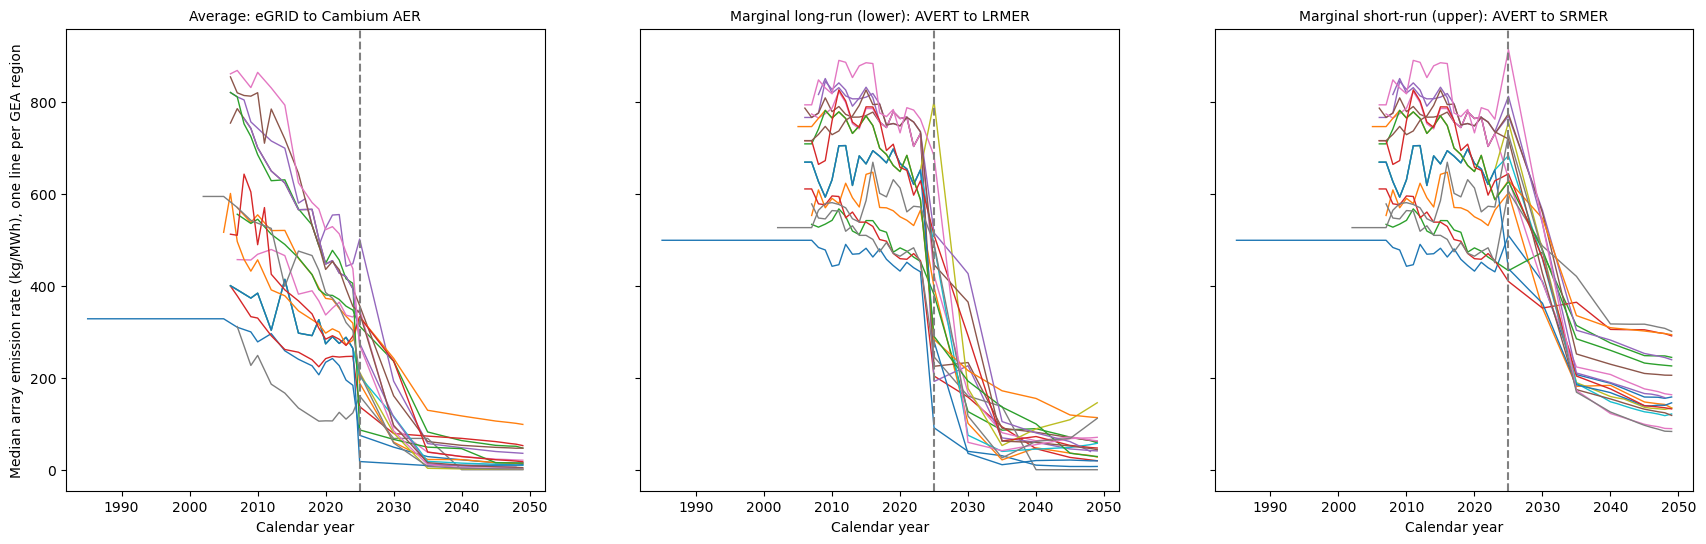

       average  marginal LR (lower, primary)  marginal SR (upper)
calYr                                                            
2022     339.0                         565.0                565.0
2023     320.0                         575.0                575.0
2024     315.0                         461.0                599.0
2025     237.0                         339.0                618.0
2026     214.0                         300.0                582.0
2027     190.0                         260.0                547.0
2028     167.0                         221.0                512.0
2029     143.0                         182.0                477.0
2030     119.0                         143.0                442.0


In [ ]:
# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Timing check: generation-weighted vs flat annual Cambium rate by region (first solve year)

timingCheck = cambiumEff[cambiumEff['year'] == firstCambiumYear].merge(arrayRegions[[arrayIDcol, 'geaRegion']], on=arrayIDcol)
timingCheck = timingCheck.groupby('geaRegion')[['rateKgMWh', 'rateFlatKgMWh', 'rateLrmerKgMWh', 'rateLrmerFlatKgMWh', 'rateSrmerKgMWh', 'rateSrmerFlatKgMWh']].median()
timingCheck['weightedToFlat'] = timingCheck['rateKgMWh'] / timingCheck['rateFlatKgMWh']
timingCheck['weightedToFlatLrmer'] = timingCheck['rateLrmerKgMWh'] / timingCheck['rateLrmerFlatKgMWh']
timingCheck['weightedToFlatSrmer'] = timingCheck['rateSrmerKgMWh'] / timingCheck['rateSrmerFlatKgMWh']
timingCheck['lrmerToAvg'] = timingCheck['rateLrmerKgMWh'] / timingCheck['rateKgMWh']
timingCheck['srmerToLrmer'] = timingCheck['rateSrmerKgMWh'] / timingCheck['rateLrmerKgMWh']
print(timingCheck.round(3).sort_values('weightedToFlat').to_string())
timingCheck.to_csv(timingCheck_path)

# ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~ Seam check: rate by year for each version (look for jumps at firstCambiumYear)

# Thin grey lines: median array rate in each GEA region; colored line: fleet generation-weighted rate
seamDF = offsetLong.merge(arrayRegions[[arrayIDcol, 'geaRegion']], on=arrayIDcol)
fig, axes = plt.subplots(1, 3, figsize=(ft.figWidth['double'], 62 * ft.mm), sharey=True, gridspec_kw={'wspace': 0.12})
panels = [('rateKgMWh', 'Avg', 'Average\neGRID \u2192 Cambium average'), ('rateMarginalLRKgMWh', 'MarginalLR', 'Marginal, long-run\nAVERT \u2192 Cambium LRMER'), ('rateMarginalSRKgMWh', 'MarginalSR', 'Marginal, short-run\nAVERT \u2192 Cambium SRMER')]
for ax, (col, v, title), letter in zip(axes, panels, 'abc'):
    byRegion = seamDF.groupby(['geaRegion', 'calYr'])[col].median().unstack('geaRegion')
    byRegion = byRegion.loc[byRegion.index >= 2005]
    for i, region in enumerate(byRegion.columns):
        ax.plot(byRegion.index, byRegion[region], color='#C3C7CC', lw=0.45, zorder=1)
    fleetYr = seamDF.assign(w=seamDF['MWh'] * seamDF[col]).groupby('calYr')[['w', 'MWh']].sum()
    fleetYr = fleetYr.loc[fleetYr.index >= 2005]
    ax.plot(fleetYr.index, fleetYr['w'] / fleetYr['MWh'], color=ft.versionColors[v], lw=1.4, zorder=3, label=ft.versionLabels[v] + ', fleet (generation-weighted)')
    ft.markProjected(ax, year=firstCambiumYear, labels=(letter == 'a'))
    ax.set_title(title, fontsize=7); ax.set_xlabel('Calendar year'); ax.set_ylim(bottom=0)
    ft.panelLabel(ax, letter, x=-0.08 if letter != 'a' else -0.2, y=1.02)
axes[0].set_ylabel('Grid emission rate (kg CO$_2$e MWh$^{-1}$)')
from matplotlib.lines import Line2D
handles = [Line2D([], [], color='#C3C7CC', lw=0.8, label='GEA region (median array)')] + [Line2D([], [], color=ft.versionColors[v], lw=1.4, label=ft.versionLabels[v] + ', fleet (generation-weighted)') for _, v, _ in panels]
fig.legend(handles=handles, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=4, fontsize=6)
ft.saveFig(fig, figure_path, 'gridRateSeam_byGEA')
plt.show()

# Fleet generation-weighted rate by year, each version (the long-run drop at firstCambiumYear is the short- to long-run definition change; short-run should be close to continuous)
fleet = offsetLong.groupby('calYr')[['MWh'] + list(tCols.values())].sum()
fleetRate = pd.DataFrame({name: fleet[c] * 1000 / fleet['MWh'] for name, c in tCols.items()})
print(fleetRate.loc[firstCambiumYear - 3:firstCambiumYear + 5].round(0))

# Export

In [ ]:
# Export long and wide offsets
offsetLong.round({'MWh': 3, 'rateKgMWh': 2, 'tCO2e': 4, 'rateMarginalLRKgMWh': 2, 'tCO2eMarginalLR': 4, 'rateMarginalSRKgMWh': 2, 'tCO2eMarginalSR': 4}).to_csv(offsetLong_path, index=False)
offsetWide.round(3).to_csv(offsetWide_path, index=False)
offsetWideMarginalLR.round(3).to_csv(offsetWideMarginalLR_path, index=False)
offsetWideMarginalSR.round(3).to_csv(offsetWideMarginalSR_path, index=False)
print('Exported to:', carbon_path)

Exported to: S:\Users\stidjaco\R_files\BigPanel\Data\Derived\carbonOffset
